In [16]:
import yfinance as yf
import pandas as pd
from pathlib import Path

# Import cached fetch helpers
from yfinance_intraday_entry import get_intraday_data, get_daily_data, DATA_DIR

# Stick with SPY as the primary symbol for this notebook.
ticker = 'SPY'
spy = yf.Ticker(ticker)

print('Ticker:', ticker)
print('Info keys:', sorted(spy.info.keys()))

hist = get_daily_data(ticker, period='5d', interval='1d')
print('History shape:', hist.shape)
print('History columns:', hist.columns.tolist())
print(hist.tail())

print('\nDividends sample:')
print(spy.dividends.head())
print('\nSplits sample:')
print(spy.splits.head())
print('\nActions sample:')
print(spy.actions.head())
print('\nMajor holders:')
print(spy.major_holders)
print('\nInstitutional holders:')
print(spy.institutional_holders)
print('\nSustainability:')
print(spy.sustainability)

print('\nData cache directory:', DATA_DIR)

Ticker: SPY
Info keys: ['allTimeHigh', 'allTimeLow', 'ask', 'askSize', 'averageDailyVolume10Day', 'averageDailyVolume3Month', 'averageVolume', 'averageVolume10days', 'beta3Year', 'bid', 'bidSize', 'bookValue', 'category', 'companyOfficers', 'corporateActions', 'cryptoTradeable', 'currency', 'customPriceAlertConfidence', 'dayHigh', 'dayLow', 'dividendYield', 'epsTrailingTwelveMonths', 'esgPopulated', 'exchange', 'exchangeDataDelayedBy', 'exchangeTimezoneName', 'exchangeTimezoneShortName', 'executiveTeam', 'fiftyDayAverage', 'fiftyDayAverageChange', 'fiftyDayAverageChangePercent', 'fiftyTwoWeekChangePercent', 'fiftyTwoWeekHigh', 'fiftyTwoWeekHighChange', 'fiftyTwoWeekHighChangePercent', 'fiftyTwoWeekLow', 'fiftyTwoWeekLowChange', 'fiftyTwoWeekLowChangePercent', 'fiftyTwoWeekRange', 'financialCurrency', 'firstTradeDateMilliseconds', 'fiveYearAverageReturn', 'fullExchangeName', 'fundFamily', 'fundInceptionDate', 'gmtOffSetMilliseconds', 'hasPrePostMarketData', 'language', 'legalType', 'lon

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"No fundamentals data found for symbol: SPY"}}}


Empty DataFrame
Columns: []
Index: []

Institutional holders:
Empty DataFrame
Columns: []
Index: []

Sustainability:


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"No fundamentals data found for symbol: SPY"}}}


Empty DataFrame
Columns: []
Index: []

Data cache directory: data


In [18]:
# Verify SPY 1-minute historical price data for the last 7 days includes HLC
from pathlib import Path
import sys, pathlib
# Ensure the src/ folder is on sys.path so we can import the helper module
src_path = pathlib.Path.cwd() / 'src'
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

try:
    from yfinance_intraday_entry import get_intraday_data, DATA_DIR
except Exception as exc:
    print('Could not import yfinance_intraday_entry:', exc)
    get_intraday_data = None
    DATA_DIR = Path('data')

if get_intraday_data is None:
    raise RuntimeError('get_intraday_data not available; ensure you ran the top import cell or that src/ is on sys.path')

spy_1m_7d = get_intraday_data(ticker, interval='1m', period='7d')
cache_file = Path(DATA_DIR) / f"{ticker}_1m_7d.csv"
print('SPY 1m 7d shape:', spy_1m_7d.shape)
print('Columns:', spy_1m_7d.columns.tolist())
print('Contains HLC:', all(col in spy_1m_7d.columns for col in ['High', 'Low', 'Close']))
print('Date range:', spy_1m_7d.index.min(), 'to', spy_1m_7d.index.max())
print(spy_1m_7d[['High', 'Low', 'Close', 'Volume']].head())
print(spy_1m_7d[['High', 'Low', 'Close', 'Volume']].tail())
print('\nCached file (on save):', cache_file)

SPY 1m 7d shape: (2730, 5)
Columns: ['Close', 'High', 'Low', 'Open', 'Volume']
Contains HLC: True
Date range: 2026-07-23 09:30:00-04:00 to 2026-07-31 15:59:00-04:00
                                 High         Low       Close   Volume
datetime                                                              
2026-07-23 09:30:00-04:00  739.409973  738.469971  739.030029  2648994
2026-07-23 09:31:00-04:00  739.770020  738.840027  739.770020   542580
2026-07-23 09:32:00-04:00  740.450012  739.770020  740.369995   466862
2026-07-23 09:33:00-04:00  740.789978  740.169983  740.739990   305123
2026-07-23 09:34:00-04:00  741.369995  740.750000  741.320007   238312
                                 High         Low       Close   Volume
datetime                                                              
2026-07-31 15:55:00-04:00  748.690002  747.960022  748.190002   620453
2026-07-31 15:56:00-04:00  748.330017  748.099976  748.190002   544597
2026-07-31 15:57:00-04:00  748.335022  747.960022  747

In [3]:
import yfinance as yf

# Create a Ticker object
msft = yf.Ticker("MSFT")

# Method A: See all available attributes and methods for the ticker
print(dir(msft))

# Method B: Print the massive dictionary of fundamental metadata available
print(msft.info.keys())

['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_analysis', '_data', '_download_options', '_earnings', '_earnings_dates', '_expirations', '_fast_info', '_fetch_ticker_tz', '_financials', '_fundamentals', '_funds_data', '_get_earnings_dates_using_scrape', '_get_earnings_dates_using_screener', '_get_ticker_tz', '_holders', '_isin', '_lazy_load_price_history', '_message_handler', '_news', '_options2df', '_price_history', '_quote', '_shares', '_tz', '_underlying', 'actions', 'analyst_price_targets', 'balance_sheet', 'balancesheet', 'calendar', 'capital_gains', 'cash_flow', 'cashflow', 'dividends', 'earnings', 'earnings_dates', 'earnings_estimate', 'earnings_history', 'eps_revisions

In [ ]:
# Compute intraday metrics
if 'df' not in globals():
    import pandas as pd
    import yfinance as yf

    ticker = 'SPY'
    interval = '5m'
    period = '30d'

    df = yf.download(ticker, interval=interval, period=period, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = [col[0] for col in df.columns]
    df = df.rename_axis('datetime').reset_index()
    df['datetime'] = pd.to_datetime(df['datetime'])
    df = df.set_index('datetime').sort_index()

df['return_1'] = df['Close'].pct_change(1)
df['return_3'] = df['Close'].pct_change(3)
df['range_pct'] = (df['High'] - df['Low']) / df['Close']
df['vwap'] = (df['Close'] * df['Volume']).cumsum() / df['Volume'].cumsum()
df['ema_10'] = df['Close'].ewm(span=10, adjust=False).mean()

df[['return_1', 'return_3', 'range_pct', 'vwap', 'ema_10']].head()

,return_1,return_3,range_pct,vwap,ema_10
datetime,,,,,
2026-06-18 09:30:00-04:00,NaN,NaN,0.003124,745.890015,745.890015
2026-06-18 09:35:00-04:00,-0.001756,NaN,0.002270,745.553780,745.651833
2026-06-18 09:40:00-04:00,-0.000739,NaN,0.001586,745.321045,745.356960
2026-06-18 09:45:00-04:00,0.001572,-0.000925,0.001880,745.269598,745.328424
2026-06-18 09:50:00-04:00,-0.000738,0.000094,0.001571,745.217308,745.205079


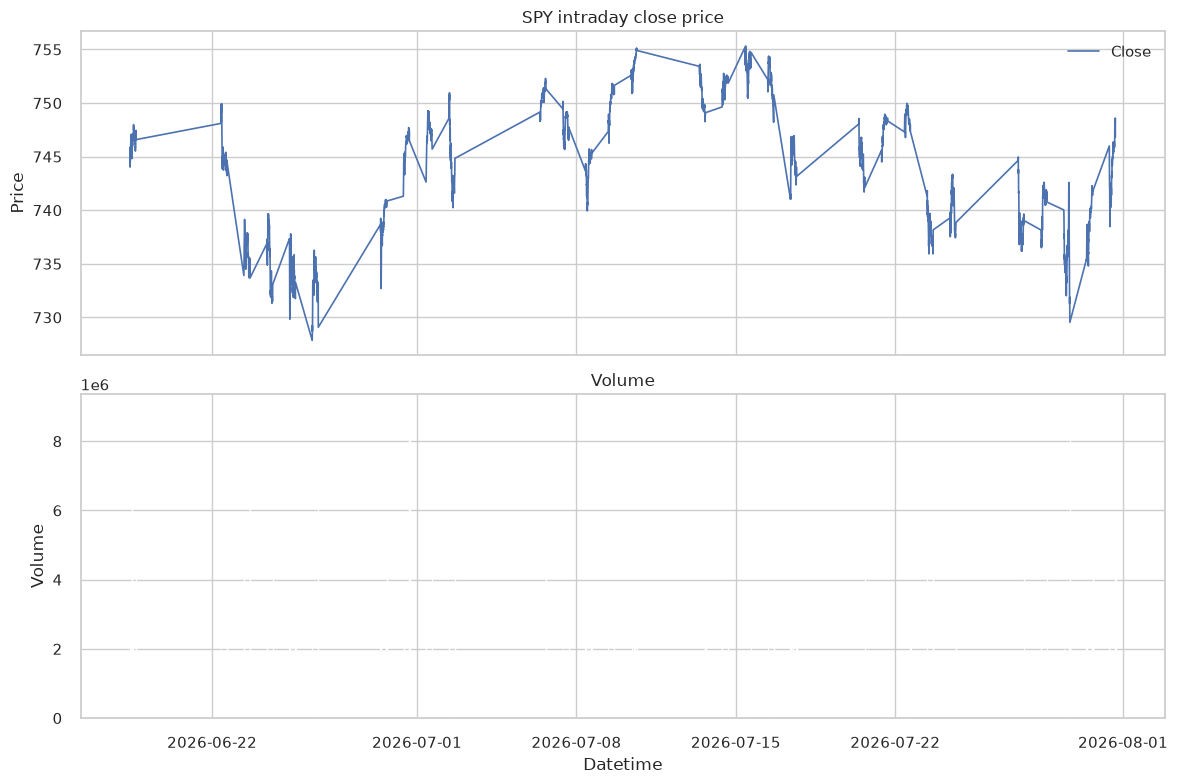

In [3]:
# Plot price and volume trends
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8')
sns.set_theme(style='whitegrid')

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(df['Close'], label='Close', linewidth=1.2)
axes[0].set_title(f'{ticker} intraday close price')
axes[0].set_ylabel('Price')
axes[0].legend()

axes[1].bar(df.index, df['Volume'], color='steelblue', width=0.01)
axes[1].set_title('Volume')
axes[1].set_ylabel('Volume')
axes[1].set_xlabel('Datetime')

plt.tight_layout()
plt.show()

In [4]:
# Inspect and clean the data
if isinstance(df.columns, pd.MultiIndex):
    df.columns = [col[0] for col in df.columns]

df = df.rename_axis('datetime').reset_index()
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.set_index('datetime')

df = df.sort_index()
df.isna().sum()

Close        0
High         0
Low          0
Open         0
Volume       0
return_1     1
return_3     3
range_pct    0
vwap         0
ema_10       0
dtype: int64

In [ ]:
ticker = 'SPY'
interval = '5m'
period = '30d'

df = yf.download(ticker, interval=interval, period=period, progress=False)

df.head()

# Intraday yfinance exploration

This notebook is a starter workspace for downloading intraday stock data, inspecting it, and exploring simple metrics and plots.